# Aircraft manufacturer classification on FGVC-Aircraft

Given a photo of an aircraft, which of 30 manufacturers built it? I wanted to see how far a small pretrained CNN gets on a fine-grained problem with very little data, so I use an ImageNet-pretrained ResNet-18, the official FGVC-Aircraft manufacturer splits (3,334 train / 3,333 val / 3,333 test), and compare three training setups against two simple baselines. The test set is only used once, at the end, for the model I picked on validation.

Outline: setup, data checks, preprocessing, Dataset/DataLoader, baselines, training, test evaluation, error analysis, inference, saving results.

The next cell downloads the dataset if `/content/fgvc-aircraft-2013b/` is missing (it is a large download). The dataset is for non-commercial research use.

In [1]:
import subprocess
from pathlib import Path

DATA_DIR = Path("/content/fgvc-aircraft-2013b/data")
DATA_URL = "https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/archives/fgvc-aircraft-2013b.tar.gz"

if DATA_DIR.exists():
    print(f"Found dataset at {DATA_DIR} — nothing to download.")
else:
    print("Dataset folder missing. Downloading and extracting (this can take a while)...")
    subprocess.run(["wget", "-q", "-O", "/content/fgvc.tar.gz", DATA_URL], check=True)
    subprocess.run(["tar", "-xzf", "/content/fgvc.tar.gz", "-C", "/content"], check=True)
    print("Done. Exists now:", DATA_DIR.exists())

Dataset folder missing. Downloading and extracting (this can take a while)...
Done. Exists now: True


## Setup

Seeds, device and a small config. Batch size and epoch count depend on whether a GPU is available (everything reported here was run on a Colab T4).

In [2]:
# ---- A.1 Imports (all in one place) ----
import os, sys, platform, random, time, json, shutil, datetime

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm
from scipy.stats import spearmanr
from IPython.display import display

import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, f1_score)

import torch
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Pillow      :", Image.__version__)

Python      : 3.13.15
PyTorch     : 2.11.0+cu130
Torchvision : 0.26.0+cu130
NumPy       : 2.1.3
pandas      : 2.2.3
scikit-learn: 1.6.1
Pillow      : 11.3.0


In [3]:
# ---- A.2 Seeds, device, hardware profile, output folders ----
SEED = 42

def set_seed(seed: int = SEED) -> None:
    """Seed every random number generator we use."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)          # harmless if there is no GPU
    torch.backends.cudnn.deterministic = True  # prefer repeatable conv algorithms
    torch.backends.cudnn.benchmark = False     # don't auto-pick (possibly varying) fastest algorithms

def seed_worker(worker_id: int) -> None:
    """Gives each DataLoader worker process its own deterministic seed (used for augmentation)."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

set_seed(SEED)

USE_GPU = torch.cuda.is_available()
DEVICE = torch.device("cuda" if USE_GPU else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if USE_GPU else None
NUM_WORKERS = min(4, os.cpu_count() or 1)

# Hardware profiles: lighter on CPU, larger batches/more epochs on GPU.
PROFILES = {
    "gpu": dict(batch_size=64, epochs_head=12, epochs_ft=15, patience=5),
    "cpu": dict(batch_size=32, epochs_head=5,  epochs_ft=4,  patience=3),
}
HW = PROFILES["gpu" if USE_GPU else "cpu"]

IMG_SIZE = 224          # ResNet-18 was trained on 224x224 crops
CACHE_SHORT_SIDE = 256  # we pre-shrink images once to this short side (big speed-up)
BANNER_PX = 20          # FGVC-Aircraft images carry a 20 px copyright banner at the bottom

# Where results go. Set USE_GOOGLE_DRIVE=True to survive Colab disconnects.
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/aircraft_outputs")
else:
    OUTPUT_DIR = Path("/content/aircraft_outputs")
CKPT_DIR, PLOTS_DIR, RESULTS_DIR = OUTPUT_DIR / "checkpoints", OUTPUT_DIR / "plots", OUTPUT_DIR / "results"
CACHE_DIR = Path("/content/aircraft_cache")
for d in (CKPT_DIR, PLOTS_DIR, RESULTS_DIR, CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Device       : {DEVICE}" + (f" ({GPU_NAME})" if USE_GPU else ""))
print(f"Profile      : {'gpu' if USE_GPU else 'cpu'} -> {HW}")
print(f"Num workers  : {NUM_WORKERS}")
print(f"Output folder: {OUTPUT_DIR}")
if not USE_GPU:
    print("\n⚠️  No GPU detected. The CPU profile is much lighter. For the full experiment set use "
          "Runtime → Change runtime type → T4 GPU and re-run from Stage A.")

Device       : cuda (Tesla T4)
Profile      : gpu -> {'batch_size': 64, 'epochs_head': 12, 'epochs_ft': 15, 'patience': 5}
Num workers  : 2
Output folder: /content/aircraft_outputs


## Looking at the data

First the split files: missing images, malformed lines, duplicate ids, ids shared between splits and labels that are not in `manufacturers.txt`. Then class counts and a few images.

In [4]:
# ---- B.1 Inspect the extracted folder ----
if not DATA_DIR.exists():
    raise FileNotFoundError(f"{DATA_DIR} not found. Run Stage 0 or fix DATA_DIR.")

IMG_DIR = DATA_DIR / "images"
print("Files in data folder:")
for p in sorted(DATA_DIR.iterdir()):
    print("  ", p.name + ("/" if p.is_dir() else ""))
print("\nJPEG files in images/:", len(list(IMG_DIR.glob("*.jpg"))))

Files in data folder:
   families.txt
   images/
   images_box.txt
   images_family_test.txt
   images_family_train.txt
   images_family_trainval.txt
   images_family_val.txt
   images_manufacturer_test.txt
   images_manufacturer_train.txt
   images_manufacturer_trainval.txt
   images_manufacturer_val.txt
   images_test.txt
   images_train.txt
   images_val.txt
   images_variant_test.txt
   images_variant_train.txt
   images_variant_trainval.txt
   images_variant_val.txt
   manufacturers.txt
   variants.txt

JPEG files in images/: 10000


In [5]:
# ---- B.2 Read official manufacturer files + full validation report ----
SPLITS = ["train", "val", "test"]
EXPECTED_COUNTS = {"train": 3334, "val": 3333, "test": 3333}   # what you verified earlier
EXPECTED_CLASSES = 30

def read_manufacturer_names(path: Path) -> list:
    names = [ln.strip() for ln in path.read_text(encoding="utf-8").splitlines() if ln.strip()]
    if len(set(names)) != len(names):
        raise ValueError("manufacturers.txt contains duplicate names")
    return names

def read_split_file(path: Path):
    """Return (DataFrame[image_id, manufacturer], list of malformed (line_no, text))."""
    records, malformed = [], []
    for line_no, line in enumerate(path.read_text(encoding="utf-8").splitlines(), start=1):
        if not line.strip():
            continue
        parts = line.strip().split(" ", 1)               # split on FIRST space only
        if len(parts) != 2 or not parts[0].isdigit() or not parts[1].strip():
            malformed.append((line_no, line))
            continue
        records.append((parts[0], parts[1].strip()))     # keep id as string (leading zeros!)
    return pd.DataFrame(records, columns=["image_id", "manufacturer"]), malformed

classes = read_manufacturer_names(DATA_DIR / "manufacturers.txt")
NUM_CLASSES = len(classes)
class_to_idx = {c: i for i, c in enumerate(classes)}   # ONE mapping used for every split
idx_to_class = {i: c for c, i in class_to_idx.items()}

raw = {}
hard_errors, warnings_ = [], []
for split in SPLITS:
    df, malformed = read_split_file(DATA_DIR / f"images_manufacturer_{split}.txt")
    df["split"] = split
    df["orig_path"] = df["image_id"].map(lambda i: str(IMG_DIR / f"{i}.jpg"))
    raw[split] = df

    n_missing = int((~df["orig_path"].map(lambda p: Path(p).exists())).sum())
    unknown = sorted(set(df["manufacturer"]) - set(classes))
    n_dup = int(df["image_id"].duplicated().sum())
    missing_classes = sorted(set(classes) - set(df["manufacturer"]))

    print(f"[{split:5s}] rows={len(df):5d} | missing files={n_missing} | malformed lines={len(malformed)} | "
          f"duplicate ids={n_dup} | unknown labels={unknown} | classes present={df['manufacturer'].nunique()}")
    if malformed:          hard_errors.append(f"{split}: malformed lines {malformed[:3]}...")
    if n_missing:          hard_errors.append(f"{split}: {n_missing} image files missing")
    if unknown:            hard_errors.append(f"{split}: labels not in manufacturers.txt: {unknown}")
    if n_dup:              hard_errors.append(f"{split}: {n_dup} duplicate image ids")
    if len(df) != EXPECTED_COUNTS[split]:
        warnings_.append(f"{split}: {len(df)} rows, expected {EXPECTED_COUNTS[split]}")
    if missing_classes:    warnings_.append(f"{split}: classes with zero images: {missing_classes}")

# leakage check: the same image id must never appear in two splits
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = set(raw[a]["image_id"]) & set(raw[b]["image_id"])
    print(f"overlap {a}/{b}: {len(overlap)}")
    if overlap:
        hard_errors.append(f"{len(overlap)} image ids shared between {a} and {b} (data leakage)")

if len(classes) != EXPECTED_CLASSES:
    warnings_.append(f"{len(classes)} classes in manufacturers.txt, expected {EXPECTED_CLASSES}")

print("\nNumber of classes:", NUM_CLASSES)
print("Warnings:", warnings_ if warnings_ else "none")
print("Hard errors:", hard_errors if hard_errors else "none")
assert not hard_errors, "Fix the hard errors above before continuing."

[train] rows= 3334 | missing files=0 | malformed lines=0 | duplicate ids=0 | unknown labels=[] | classes present=30
[val  ] rows= 3333 | missing files=0 | malformed lines=0 | duplicate ids=0 | unknown labels=[] | classes present=30
[test ] rows= 3333 | missing files=0 | malformed lines=0 | duplicate ids=0 | unknown labels=[] | classes present=30
overlap train/val: 0
overlap train/test: 0
overlap val/test: 0

Number of classes: 30
Warnings: none
Hard errors: none


Sampled 300 training images — size summary:


,width,height
count,300.0,300.0
mean,1105.5,751.0
std,171.7,118.0
min,800.0,468.0
25%,1024.0,691.0
50%,1024.0,698.0
75%,1200.0,812.0
max,1600.0,1082.0


manufacturer,Boeing,Airbus,Embraer,McDonnell Douglas,de Havilland,Canadair,Douglas Aircraft Company,Cessna,British Aerospace,Fokker,...,Antonov,Lockheed Martin,Cirrus Aircraft,Bombardier Aerospace,Fairchild,Eurofighter,Ilyushin,Piper,Robin,Supermarine
train,733,434,233,232,167,134,133,133,133,100,...,34,34,33,33,33,33,33,33,33,33
val,733,433,234,235,167,133,134,133,134,100,...,33,33,33,34,33,33,33,34,33,33
test,734,433,233,233,166,133,133,134,133,100,...,33,33,34,33,34,34,34,33,34,34



Train imbalance ratio (largest/smallest class): 22.2x
Largest class: Boeing (733), smallest: Cirrus Aircraft (33)
Share of train set that is the single most common class: 22.0%


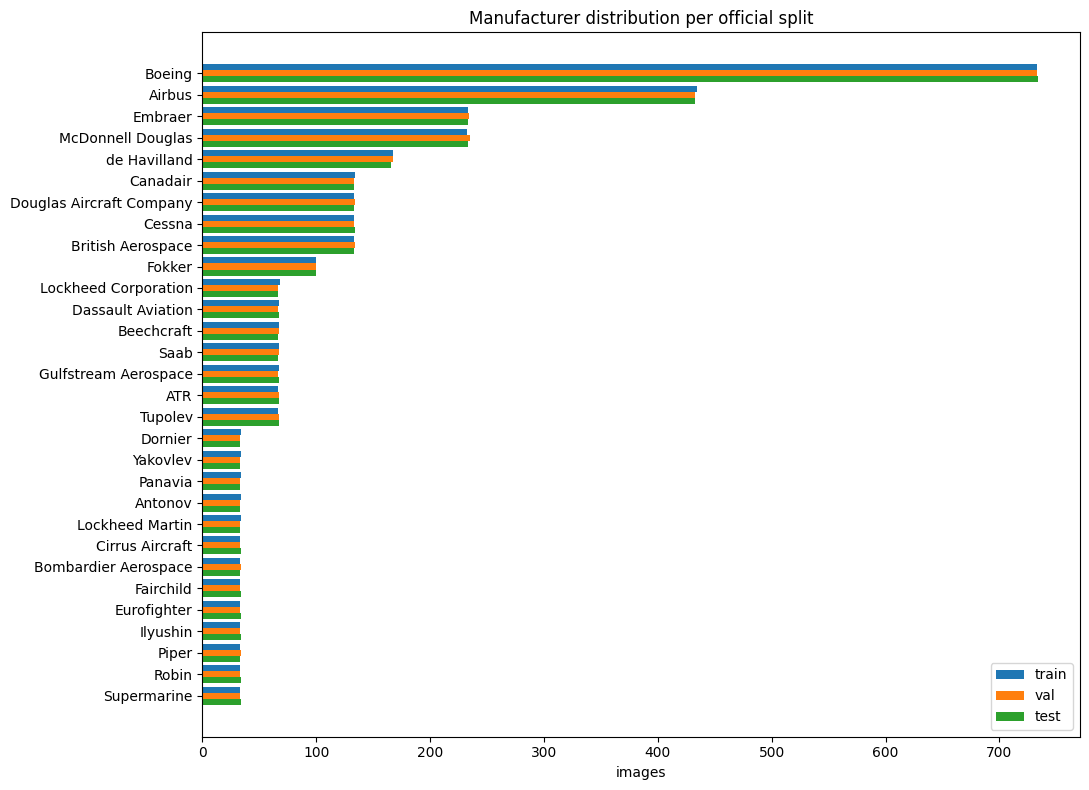

In [6]:
# ---- B.3 Image sizes (lazy open: reads only the header, so it is fast) ----
sample = raw["train"].sample(300, random_state=SEED)
sizes = []
for p in sample["orig_path"]:
    with Image.open(p) as im:
        sizes.append(im.size)
sizes = pd.DataFrame(sizes, columns=["width", "height"])
print("Sampled 300 training images — size summary:")
display(sizes.describe().round(1))

# ---- B.4 Class distribution ----
counts = pd.DataFrame({s: raw[s]["manufacturer"].value_counts() for s in SPLITS}).reindex(classes).fillna(0).astype(int)
counts = counts.sort_values("train", ascending=False)
display(counts.T)
print(f"\nTrain imbalance ratio (largest/smallest class): {counts['train'].max() / counts['train'].min():.1f}x")
print(f"Largest class: {counts['train'].idxmax()} ({counts['train'].max()}), smallest: {counts['train'].idxmin()} ({counts['train'].min()})")
print(f"Share of train set that is the single most common class: {counts['train'].max() / counts['train'].sum():.1%}")

fig, ax = plt.subplots(figsize=(11, 8))
y = np.arange(len(counts)); h = 0.28
for k, s in enumerate(SPLITS):
    ax.barh(y + (k - 1) * h, counts[s], height=h, label=s)
ax.set_yticks(y); ax.set_yticklabels(counts.index); ax.invert_yaxis()
ax.set_xlabel("images"); ax.set_title("Manufacturer distribution per official split"); ax.legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "class_distribution.png", dpi=150); plt.show()

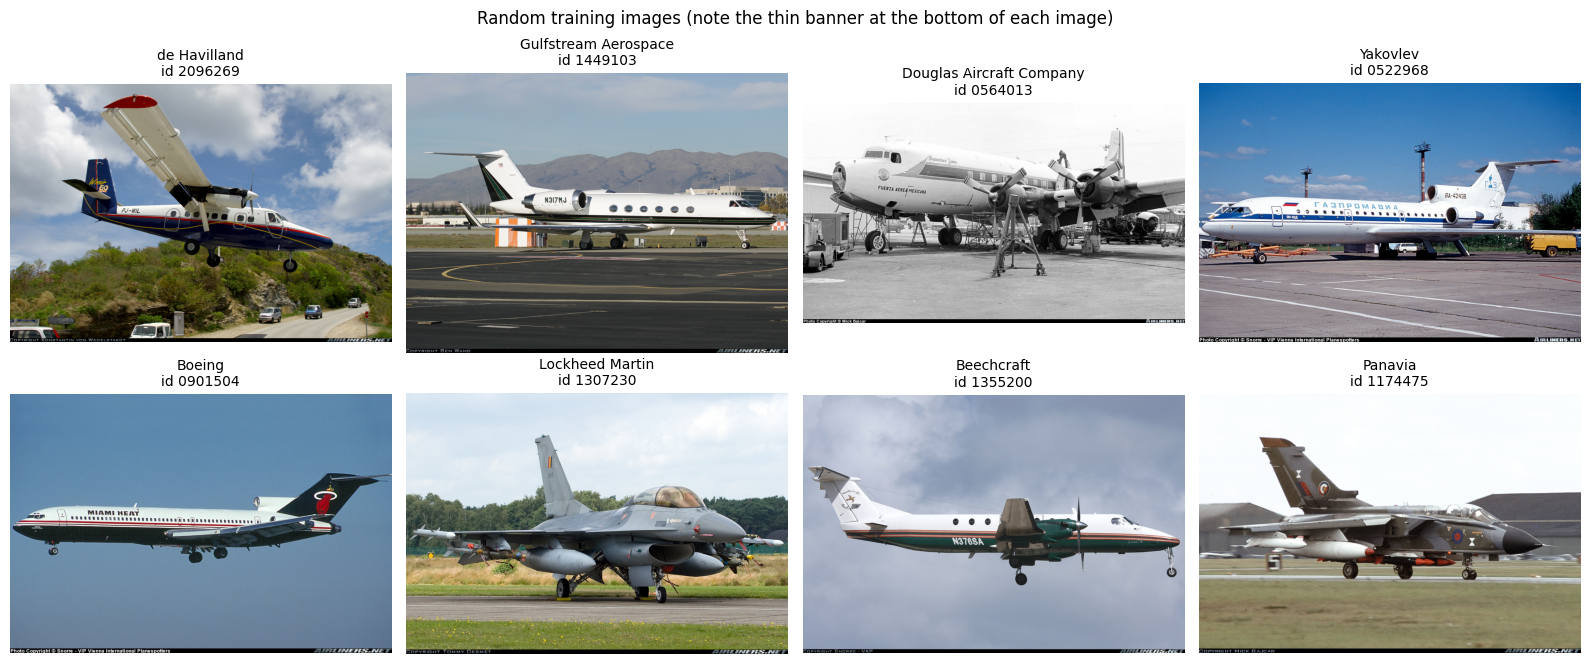

In [7]:
# ---- B.5 Look at real images with their labels (ORIGINAL files, banner still visible) ----
demo = raw["train"].sample(8, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (_, r) in zip(axes.ravel(), demo.iterrows()):
    with Image.open(r["orig_path"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"{r['manufacturer']}\nid {r['image_id']}", fontsize=10); ax.axis("off")
plt.suptitle("Random training images (note the thin banner at the bottom of each image)")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "sample_images.png", dpi=120); plt.show()

## Preprocessing

Two things stood out in the data:

- The classes are very uneven. Boeing has 733 training images (22% of the set), the smallest classes have 33.
- Every image has a 20 px copyright strip at the bottom. I crop it off so the model cannot pick up on text instead of the aircraft.

The photos are large, so I resize them once (short side 256 px) into a cache folder and load from there. At load time images are resized to 224x224 and normalised with the ImageNet mean/std that the pretrained weights expect. Training adds a random resized crop and a horizontal flip; validation and test are deterministic.

In [8]:
# ---- C.1 One-off preprocessing cache (resumable: skips files that already exist) ----
def preprocess_to_cache(orig_path: str, cache_path: Path) -> None:
    with Image.open(orig_path) as im:
        im = im.convert("RGB")
        w, h = im.size
        im = im.crop((0, 0, w, h - BANNER_PX))            # remove copyright banner
        w, h = im.size
        scale = CACHE_SHORT_SIDE / min(w, h)
        if scale < 1:                                      # only ever shrink, never upscale
            im = im.resize((round(w * scale), round(h * scale)), Image.Resampling.BICUBIC)
        im.save(cache_path, format="JPEG", quality=95)

failures = []
t0 = time.time()
for split in SPLITS:
    df = raw[split]
    cache_paths = []
    for image_id, orig in tqdm(zip(df["image_id"], df["orig_path"]), total=len(df), desc=f"cache {split}"):
        cp = CACHE_DIR / f"{image_id}.jpg"
        if not cp.exists():
            try:
                preprocess_to_cache(orig, cp)
            except (OSError, UnidentifiedImageError) as e:     # corrupted / unreadable image
                failures.append((split, image_id, repr(e)))
        cache_paths.append(str(cp))
    df["image_path"] = cache_paths
print(f"Caching finished in {time.time() - t0:.0f}s. Failed images: {len(failures)}")
if failures:
    print(failures[:10])
    raise RuntimeError("Some images could not be read — see the list above (split, image_id, error).")

Caching finished in 182s. Failed images: 0


In [9]:
# ---- C.2 Final DataFrames: every split gets label + image_path BEFORE training ----
REQUIRED_COLUMNS = ["image_id", "manufacturer", "label", "split", "orig_path", "image_path"]

def validate_df(df: pd.DataFrame, split: str) -> None:
    """Fail early (with a clear message) instead of crashing mid-training with KeyError."""
    missing_cols = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing_cols:
        raise KeyError(f"[{split}] DataFrame is missing columns {missing_cols}; has {list(df.columns)}")
    if df[REQUIRED_COLUMNS].isna().any().any():
        raise ValueError(f"[{split}] NaN values found:\n{df[REQUIRED_COLUMNS].isna().sum()}")
    bad = [p for p in df["image_path"] if not Path(p).exists()]
    if bad:
        raise FileNotFoundError(f"[{split}] {len(bad)} image files missing, e.g. {bad[:3]}")
    if not df["label"].between(0, NUM_CLASSES - 1).all():
        raise ValueError(f"[{split}] labels outside 0..{NUM_CLASSES - 1}")

dfs = {}
for split in SPLITS:
    df = raw[split].copy()
    df["label"] = df["manufacturer"].map(class_to_idx)        # same mapping for all splits
    df = df[REQUIRED_COLUMNS].reset_index(drop=True)
    validate_df(df, split)
    dfs[split] = df
    print(f"[{split}] OK  rows={len(df)}  columns={list(df.columns)}")

train_df, val_df, test_df = dfs["train"], dfs["val"], dfs["test"]
display(train_df.head(3))
print("\nClass -> index mapping (first 5):", dict(list(class_to_idx.items())[:5]))

[train] OK  rows=3334  columns=['image_id', 'manufacturer', 'label', 'split', 'orig_path', 'image_path']
[val] OK  rows=3333  columns=['image_id', 'manufacturer', 'label', 'split', 'orig_path', 'image_path']
[test] OK  rows=3333  columns=['image_id', 'manufacturer', 'label', 'split', 'orig_path', 'image_path']


,image_id,manufacturer,label,split,orig_path,image_path
0,1025794,Boeing,4,train,/content/fgvc-aircraft-2013b/data/images/10257...,/content/aircraft_cache/1025794.jpg
1,1340192,Boeing,4,train,/content/fgvc-aircraft-2013b/data/images/13401...,/content/aircraft_cache/1340192.jpg
2,0056978,Boeing,4,train,/content/fgvc-aircraft-2013b/data/images/00569...,/content/aircraft_cache/0056978.jpg



Class -> index mapping (first 5): {'ATR': 0, 'Airbus': 1, 'Antonov': 2, 'Beechcraft': 3, 'Boeing': 4}


In [10]:
# ---- C.3 Transforms ----
weights = models.ResNet18_Weights.IMAGENET1K_V1
_imagenet = weights.transforms()                 # reads the official preprocessing recipe (does NOT download weights)
MEAN, STD = list(_imagenet.mean), list(_imagenet.std)
print("Normalisation from pretrained weights -> mean:", MEAN, "std:", STD)

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(1.0, 1.8)),  # mild zoom/crop, plane-friendly aspect
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tfms = transforms.Compose([                # deterministic: used for val, test and inference
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

Normalisation from pretrained weights -> mean: [0.485, 0.456, 0.406] std: [0.229, 0.224, 0.225]


## Dataset and DataLoader

A small custom `Dataset` that checks the columns, paths and labels up front, and raises an error naming the image if one fails to load instead of skipping it silently. Shuffling is seeded so runs repeat.

In [11]:
class AircraftDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None, split_name: str = "?"):
        validate_df(df, split_name)
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.split_name = split_name

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        try:
            with Image.open(row["image_path"]) as im:
                img = im.convert("RGB")
        except (FileNotFoundError, UnidentifiedImageError, OSError) as e:
            raise RuntimeError(f"[{self.split_name}] failed to load idx={idx}, image_id={row['image_id']}, "
                               f"path={row['image_path']}: {e}") from e
        if self.transform is not None:
            img = self.transform(img)
        return img, int(row["label"])

datasets = {
    "train": AircraftDataset(train_df, train_tfms, "train"),
    "val":   AircraftDataset(val_df,   eval_tfms,  "val"),
    "test":  AircraftDataset(test_df,  eval_tfms,  "test"),
}

def make_loader(split: str, shuffle: bool = False, seed: int = SEED) -> DataLoader:
    g = torch.Generator()
    g.manual_seed(seed)                        # reproducible shuffling order
    return DataLoader(datasets[split], batch_size=HW["batch_size"], shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=USE_GPU,
                      worker_init_fn=seed_worker, generator=g)

loaders = {s: make_loader(s, shuffle=(s == "train")) for s in SPLITS}
for s in SPLITS:
    print(f"{s:5s}: {len(datasets[s])} images -> {len(loaders[s])} batches of up to {HW['batch_size']}")

train: 3334 images -> 53 batches of up to 64
val  : 3333 images -> 53 batches of up to 64
test : 3333 images -> 53 batches of up to 64


batch images: (64, 3, 224, 224) torch.float32 | batch labels: (64,) torch.int64
pixel range after normalisation: [-2.12, 2.64]
✅ Labels in the first val batch match the DataFrame rows.


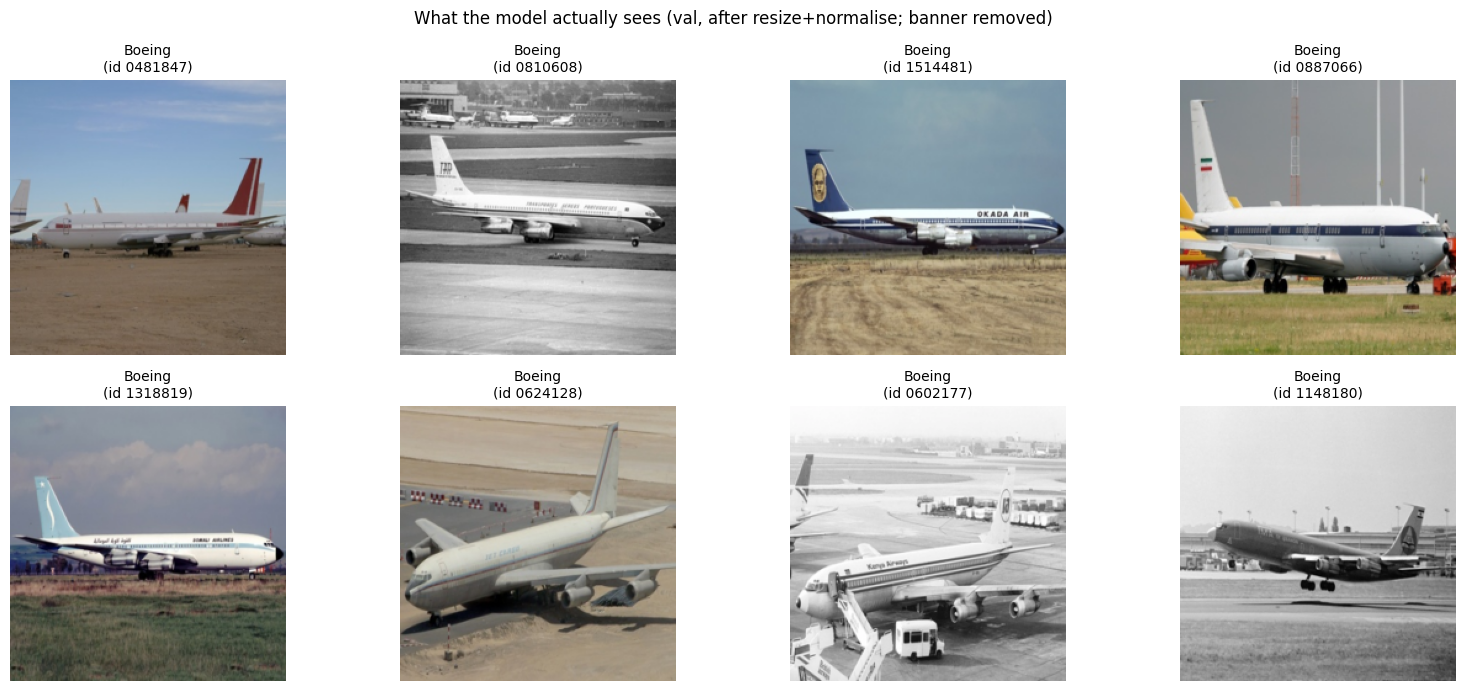

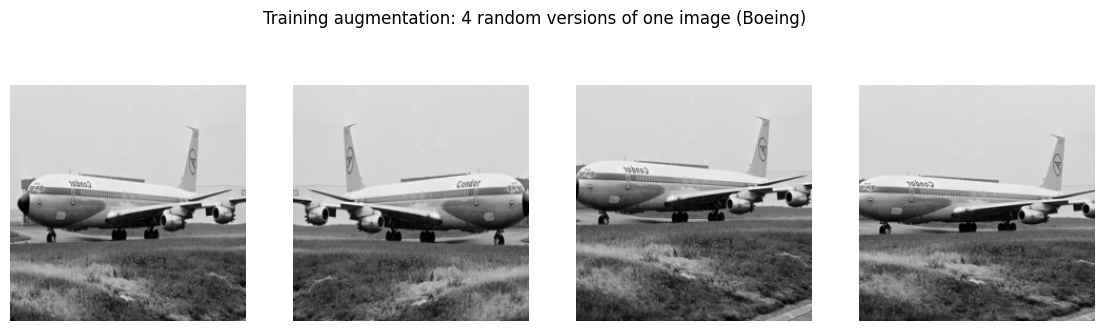

In [12]:
# ---- D.2 Sanity checks: shapes, value ranges, and image<->label pairing ----
def denorm(t: torch.Tensor) -> torch.Tensor:
    """Undo Normalize for display."""
    m = torch.tensor(MEAN).view(3, 1, 1); s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1)

images, labels = next(iter(loaders["val"]))          # val loader: no shuffle, deterministic
print("batch images:", tuple(images.shape), images.dtype, "| batch labels:", tuple(labels.shape), labels.dtype)
print(f"pixel range after normalisation: [{images.min():.2f}, {images.max():.2f}]")

expected = torch.tensor(val_df["label"].values[:len(labels)])
assert torch.equal(labels, expected), "Labels from the DataLoader do not match the DataFrame order!"
print("✅ Labels in the first val batch match the DataFrame rows.")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, img, lab, iid in zip(axes.ravel(), images[:8], labels[:8], val_df["image_id"][:8]):
    ax.imshow(denorm(img).permute(1, 2, 0)); ax.set_title(f"{idx_to_class[int(lab)]}\n(id {iid})", fontsize=10); ax.axis("off")
plt.suptitle("What the model actually sees (val, after resize+normalise; banner removed)")
plt.tight_layout(); plt.show()

# Training augmentation check: same image, 4 random augmentations
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax in axes:
    ax.imshow(denorm(datasets["train"][0][0]).permute(1, 2, 0)); ax.axis("off")
plt.suptitle(f"Training augmentation: 4 random versions of one image ({train_df.loc[0, 'manufacturer']})"); plt.show()

## Baselines and model

Majority class and logistic regression on 32x32 pixels give me something to compare against. The model is ResNet-18 with the last layer replaced by a 512 -> 30 linear layer. `trainable="head"` trains only that layer, `trainable="layer4"` also unfreezes the last residual block.

In [13]:
# ---- E.1 Metric helper (used everywhere so numbers are computed consistently) ----
LABELS = list(range(NUM_CLASSES))

def summarize_metrics(y_true, y_pred) -> dict:
    out = {"accuracy": float(accuracy_score(y_true, y_pred))}
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average=avg, zero_division=0)
        out.update({f"{avg}_precision": float(p), f"{avg}_recall": float(r), f"{avg}_f1": float(f)})
    return out

# ---- E.2 Baseline 1: majority class (fitted on TRAIN only, scored on VAL) ----
majority_label = int(train_df["label"].value_counts().idxmax())
print(f"Majority class from training data: {idx_to_class[majority_label]}")
val_majority = summarize_metrics(val_df["label"].values, np.full(len(val_df), majority_label))
baseline_val = {"majority_class": val_majority}
display(pd.DataFrame(val_majority, index=["majority_class (val)"]).round(4))

Majority class from training data: Boeing


,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
majority_class (val),0.2199,0.0073,0.0333,0.012,0.0484,0.2199,0.0793


In [14]:
# ---- E.3 Baseline 2 (optional): raw 32x32 pixels + logistic regression ----
RUN_PIXEL_BASELINE = True

def load_pixel_features(df: pd.DataFrame, size: int = 32) -> np.ndarray:
    X = np.zeros((len(df), size * size * 3), dtype=np.float32)
    for i, p in enumerate(tqdm(df["image_path"], desc="pixel features", leave=False)):
        with Image.open(p) as im:
            small = im.convert("RGB").resize((size, size), Image.Resampling.BILINEAR)
        X[i] = np.asarray(small, dtype=np.float32).ravel() / 255.0
    return X

pixel_scaler, pixel_clf = None, None
if RUN_PIXEL_BASELINE:
    t0 = time.time()
    X_train = load_pixel_features(train_df)
    pixel_scaler = StandardScaler().fit(X_train)                       # statistics from TRAIN only
    pixel_clf = LogisticRegression(max_iter=300).fit(pixel_scaler.transform(X_train), train_df["label"].values)
    X_val = load_pixel_features(val_df)
    val_pixel = summarize_metrics(val_df["label"].values, pixel_clf.predict(pixel_scaler.transform(X_val)))
    baseline_val["pixel_logreg"] = val_pixel
    print(f"Pixel baseline done in {time.time() - t0:.0f}s (a ConvergenceWarning here is normal and not an error).")
    display(pd.DataFrame(val_pixel, index=["pixel_logreg (val)"]).round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Pixel baseline done in 56s (a ConvergenceWarning here is normal and not an error).


,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
pixel_logreg (val),0.2604,0.2607,0.2066,0.2245,0.262,0.2604,0.2574


In [15]:
# ---- E.4 Build the ResNet-18 transfer-learning model ----
def build_model(trainable: str = "head", pretrained: bool = True) -> nn.Module:
    """trainable: 'head' = only the new fc layer; 'layer4' = last residual block + fc."""
    model = models.resnet18(weights=weights if pretrained else None)   # downloads ImageNet weights once
    for p in model.parameters():
        p.requires_grad = False                                        # freeze everything first
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)            # NEW output layer (trainable by default): 512 -> 30
    if trainable == "layer4":
        for p in model.layer4.parameters():
            p.requires_grad = True
    elif trainable != "head":
        raise ValueError("trainable must be 'head' or 'layer4'")
    return model.to(DEVICE)

def count_params(model: nn.Module):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

for mode in ("head", "layer4"):
    m = build_model(mode)
    tot, tr = count_params(m)
    print(f"trainable='{mode}': {tr:,} trainable of {tot:,} parameters ({tr / tot:.1%})")
print("\nOutput layer:", m.fc)
del m

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 158MB/s]


trainable='head': 15,390 trainable of 11,191,902 parameters (0.1%)
trainable='layer4': 8,409,118 trainable of 11,191,902 parameters (75.1%)

Output layer: Linear(in_features=512, out_features=30, bias=True)


## Training

Cross-entropy loss, AdamW (weight decay 0.01) and cosine learning-rate decay. When fine-tuning, the new layer uses lr 1e-3 and `layer4` uses 1e-4. A checkpoint is saved only when validation macro-F1 improves (macro-F1 rather than accuracy because of the imbalance), and early stopping uses the same number. Frozen blocks are kept in eval mode so their BatchNorm statistics do not change.

Three experiments: (1) frozen backbone, (2) fine-tune `layer4`, (3) fine-tune `layer4` with a class-weighted loss.

In [16]:
# ---- F.1 Core functions ----
def set_train_mode(model: nn.Module) -> None:
    model.train()
    for child in model.children():
        if not any(p.requires_grad for p in child.parameters()):
            child.eval()          # frozen block -> keep BatchNorm statistics fixed

def run_epoch(model, loader, criterion, optimizer=None, desc=""):
    """One pass over `loader`. Trains if an optimizer is given, otherwise evaluates (no gradients)."""
    training = optimizer is not None
    total_loss, correct, seen = 0.0, 0, 0
    all_preds, all_tgts = [], []
    with (torch.enable_grad() if training else torch.inference_mode()):
        for images, targets in tqdm(loader, desc=desc, leave=False):
            images = images.to(DEVICE, non_blocking=True)
            targets = targets.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            preds = logits.argmax(dim=1)
            total_loss += loss.item() * images.size(0)
            correct += (preds == targets).sum().item()
            seen += images.size(0)
            all_preds.append(preds.cpu()); all_tgts.append(targets.cpu())
    return {"loss": total_loss / seen, "acc": correct / seen,
            "preds": torch.cat(all_preds).numpy(), "targets": torch.cat(all_tgts).numpy()}

def save_checkpoint(path, model, meta: dict) -> None:
    path = Path(path); tmp = path.with_suffix(".tmp")
    state = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    torch.save({"model_state": state, "meta": meta}, tmp)
    os.replace(tmp, path)                                   # atomic swap: never a half-written file

def load_checkpoint(path, model):
    ckpt = torch.load(path, map_location=DEVICE, weights_only=True)
    model.load_state_dict(ckpt["model_state"])
    return ckpt["meta"]

def make_optimizer(model, lr_head, lr_backbone, weight_decay=0.01):
    head = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith("fc.")]
    backbone = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith("fc.")]
    groups = [{"params": head, "lr": lr_head}]
    if backbone:
        groups.append({"params": backbone, "lr": lr_backbone})
    return torch.optim.AdamW(groups, weight_decay=weight_decay)

def train_model(model, exp, train_loader, val_loader, train_criterion, val_criterion,
                optimizer, scheduler, ckpt_path):
    epochs, patience = exp["epochs"], HW["patience"]
    history, best_f1, best_epoch, best_m, bad = [], -1.0, 0, {}, 0
    t_start = time.time()
    try:
        for epoch in range(1, epochs + 1):
            t0 = time.time()
            set_train_mode(model)
            tr = run_epoch(model, train_loader, train_criterion, optimizer, desc="train")
            model.eval()
            va = run_epoch(model, val_loader, val_criterion, None, desc="val")
            val_f1 = float(f1_score(va["targets"], va["preds"], labels=LABELS, average="macro", zero_division=0))
            lr_now = optimizer.param_groups[0]["lr"]
            scheduler.step()
            secs = time.time() - t0

            improved = val_f1 > best_f1 + 1e-4
            if improved:
                best_f1, best_epoch, bad = val_f1, epoch, 0
                best_m = {"val_acc": va["acc"], "val_loss": va["loss"]}
                save_checkpoint(ckpt_path, model, {
                    "arch": "resnet18", "exp": exp["name"], "epoch": epoch, "val_macro_f1": val_f1,
                    "val_acc": va["acc"], "val_loss": va["loss"], "num_classes": NUM_CLASSES,
                    "class_to_idx": class_to_idx, "img_size": IMG_SIZE, "mean": MEAN, "std": STD,
                    "config": {k: v for k, v in exp.items()}})
            else:
                bad += 1

            history.append({"epoch": epoch, "train_loss": tr["loss"], "train_acc": tr["acc"],
                            "val_loss": va["loss"], "val_acc": va["acc"], "val_macro_f1": val_f1,
                            "lr": lr_now, "epoch_seconds": secs})
            print(f"[{exp['name']}] epoch {epoch:02d}/{epochs} | train loss {tr['loss']:.4f} acc {tr['acc']:.4f} | "
                  f"val loss {va['loss']:.4f} acc {va['acc']:.4f} macroF1 {val_f1:.4f} | "
                  f"lr {lr_now:.2e} | {secs:.1f}s" + ("  ✅ saved best" if improved else ""))
            if bad >= patience:
                print(f"Early stopping: no val macro-F1 improvement for {patience} epochs.")
                break
    except KeyboardInterrupt:
        print("⏹️  Training interrupted by user — restoring best saved checkpoint (if any).")

    if best_epoch > 0:
        load_checkpoint(ckpt_path, model)         # leave the model at its BEST weights, not the last epoch's
    return history, {"name": exp["name"], "config": exp, "best_epoch": best_epoch,
                     "best_val_macro_f1": best_f1, "best_val_acc": best_m.get("val_acc"),
                     "best_val_loss": best_m.get("val_loss"), "epochs_run": len(history),
                     "train_time_sec": time.time() - t_start, "ckpt_path": str(ckpt_path)}

# ---- F.2 Experiments (one major change at a time) ----
counts_train = train_df["label"].value_counts().reindex(LABELS)
class_weights = torch.tensor((len(train_df) / (NUM_CLASSES * counts_train)).values, dtype=torch.float32)
print(f"Class weights range: {class_weights.min():.2f} (most common class) to {class_weights.max():.2f} (rarest class)")

EXPERIMENTS = [
    dict(name="exp1_frozen_head", trainable="head", lr_head=1e-3, lr_backbone=0.0,
         epochs=HW["epochs_head"], class_weighted=False),
    dict(name="exp2_finetune_layer4", trainable="layer4", lr_head=1e-3, lr_backbone=1e-4,
         epochs=HW["epochs_ft"], class_weighted=False),
    dict(name="exp3_finetune_layer4_weighted", trainable="layer4", lr_head=1e-3, lr_backbone=1e-4,
         epochs=HW["epochs_ft"], class_weighted=True),
]
# On CPU we run only exp1+exp2 by default (exp3 is the same cost again). Edit this list freely.
RUN_EXPERIMENTS = [e["name"] for e in EXPERIMENTS] if USE_GPU else [e["name"] for e in EXPERIMENTS[:2]]
print("Will run:", RUN_EXPERIMENTS)

def run_experiment(exp: dict) -> dict:
    set_seed(SEED)                                          # every experiment starts from the same seed
    model = build_model(exp["trainable"])
    tr_loader, va_loader = make_loader("train", shuffle=True), make_loader("val")
    w = class_weights.to(DEVICE) if exp["class_weighted"] else None
    train_criterion = nn.CrossEntropyLoss(weight=w)
    val_criterion = nn.CrossEntropyLoss()                   # unweighted, so val loss is comparable across experiments
    optimizer = make_optimizer(model, exp["lr_head"], exp["lr_backbone"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=exp["epochs"])
    total, trainable = count_params(model)
    print(f"\n=== {exp['name']} | trainable params: {trainable:,}/{total:,} | config: {exp} ===")
    history, summary = train_model(model, exp, tr_loader, va_loader, train_criterion, val_criterion,
                                   optimizer, scheduler, CKPT_DIR / f"{exp['name']}_best.pt")
    summary["history"] = history
    print(f"→ best epoch {summary['best_epoch']} | val macro-F1 {summary['best_val_macro_f1']:.4f} | "
          f"val acc {summary['best_val_acc']:.4f} | total {summary['train_time_sec'] / 60:.1f} min")
    return summary

Class weights range: 0.15 (most common class) to 3.37 (rarest class)
Will run: ['exp1_frozen_head', 'exp2_finetune_layer4', 'exp3_finetune_layer4_weighted']


In [17]:
# ---- F.3 Run the FIRST experiment (frozen backbone) ----
exp_results = {}
exp_results[EXPERIMENTS[0]["name"]] = run_experiment(EXPERIMENTS[0])


=== exp1_frozen_head | trainable params: 15,390/11,191,902 | config: {'name': 'exp1_frozen_head', 'trainable': 'head', 'lr_head': 0.001, 'lr_backbone': 0.0, 'epochs': 12, 'class_weighted': False} ===


[exp1_frozen_head] epoch 01/12 | train loss 2.7687 acc 0.2292 | val loss 2.5105 acc 0.2415 macroF1 0.0414 | lr 1.00e-03 | 25.7s  ✅ saved best


[exp1_frozen_head] epoch 02/12 | train loss 2.2901 acc 0.3029 | val loss 2.2274 acc 0.3069 macroF1 0.1617 | lr 9.83e-04 | 42.3s  ✅ saved best


[exp1_frozen_head] epoch 03/12 | train loss 2.0597 acc 0.3674 | val loss 2.0394 acc 0.3612 macroF1 0.2606 | lr 9.33e-04 | 23.0s  ✅ saved best


Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[exp1_frozen_head] epoch 10/12 | train loss 1.5320 acc 0.5381 | val loss 1.7322 acc 0.4635 macroF1 0.4366 | lr 1.46e-04 | 23.4s  ✅ saved best


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[exp1_frozen_head] epoch 11/12 | train loss 1.5232 acc 0.5426 | val loss 1.7292 acc 0.4623 macroF1 0.4387 | lr 6.70e-05 | 24.2s  ✅ saved best


[exp1_frozen_head] epoch 12/12 | train loss 1.5182 acc 0.5453 | val loss 1.7279 acc 0.4650 macroF1 0.4431 | lr 1.70e-05 | 22.9s  ✅ saved best
→ best epoch 12 | val macro-F1 0.4431 | val acc 0.4650 | total 5.4 min


In [18]:
# ---- F.4 Run the remaining experiments (fine-tuning; weighted loss on GPU) ----
for exp in EXPERIMENTS[1:]:
    if exp["name"] in RUN_EXPERIMENTS and exp["name"] not in exp_results:
        exp_results[exp["name"]] = run_experiment(exp)

# ---- Comparison table (VALIDATION metrics only — test set is still untouched) ----
exp_table = pd.DataFrame([{
    "experiment": r["name"], "trainable": r["config"]["trainable"],
    "class_weighted": r["config"]["class_weighted"], "lr_backbone": r["config"]["lr_backbone"],
    "best_epoch": r["best_epoch"], "val_macro_f1": r["best_val_macro_f1"],
    "val_acc": r["best_val_acc"], "val_loss": r["best_val_loss"],
    "train_minutes": r["train_time_sec"] / 60} for r in exp_results.values()]).set_index("experiment")
display(exp_table.round(4))

selected_name = max(exp_results, key=lambda k: exp_results[k]["best_val_macro_f1"])
print(f"\nSelected model (highest validation macro-F1): {selected_name}")
print("Note: differences of ~1 point between experiments may be within run-to-run noise "
      "(single seed, 3.3k validation images). Do not over-interpret small gaps.")


=== exp2_finetune_layer4 | trainable params: 8,409,118/11,191,902 | config: {'name': 'exp2_finetune_layer4', 'trainable': 'layer4', 'lr_head': 0.001, 'lr_backbone': 0.0001, 'epochs': 15, 'class_weighted': False} ===


[exp2_finetune_layer4] epoch 01/15 | train loss 2.2405 acc 0.3461 | val loss 1.6473 acc 0.4716 macroF1 0.3617 | lr 1.00e-03 | 23.7s  ✅ saved best


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[exp2_finetune_layer4] epoch 02/15 | train loss 1.2655 acc 0.6206 | val loss 1.2230 acc 0.6028 macroF1 0.5429 | lr 9.89e-04 | 24.1s  ✅ saved best


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
Exception ignored in:     if w.is_alive():<function _MultiProcessingDataLoaderIter.__del__ at 0x7ec2033e53a0>
Traceback (most recent call last):

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        assert self._parent_pid == os.getpid(), 'can only test a child process'self._shutdown_workers()
AssertionError
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
:   File "/usr/lib/python3.13/multiprocessing/pro

...

[exp3_finetune_layer4_weighted] epoch 13/15 | train loss 0.1061 acc 0.9145 | val loss 0.8353 acc 0.7213 macroF1 0.7794 | lr 9.55e-05 | 42.3s  ✅ saved best


[exp3_finetune_layer4_weighted] epoch 14/15 | train loss 0.1020 acc 0.9100 | val loss 0.8272 acc 0.7240 macroF1 0.7801 | lr 4.32e-05 | 42.8s  ✅ saved best


[exp3_finetune_layer4_weighted] epoch 15/15 | train loss 0.0974 acc 0.9256 | val loss 0.8332 acc 0.7210 macroF1 0.7787 | lr 1.09e-05 | 22.5s
→ best epoch 14 | val macro-F1 0.7801 | val acc 0.7240 | total 8.0 min


,trainable,class_weighted,lr_backbone,best_epoch,val_macro_f1,val_acc,val_loss,train_minutes
experiment,,,,,,,,
exp1_frozen_head,head,False,0.0000,12,0.4431,0.4650,1.7279,5.3661
exp2_finetune_layer4,layer4,False,0.0001,12,0.7857,0.7579,0.7813,7.7342
exp3_finetune_layer4_weighted,layer4,True,0.0001,14,0.7801,0.7240,0.8272,7.9665



Selected model (highest validation macro-F1): exp2_finetune_layer4
Note: differences of ~1 point between experiments may be within run-to-run noise (single seed, 3.3k validation images). Do not over-interpret small gaps.


### Validation results

| experiment | best epoch | val macro-F1 | val accuracy | train time |
|---|---|---|---|---|
| exp1 frozen head | 12 | 0.4431 | 0.4650 | 5.4 min |
| exp2 fine-tune layer4 | 12 | 0.7857 | 0.7579 | 7.7 min |
| exp3 fine-tune layer4 + class weights | 14 | 0.7801 | 0.7240 | 8.0 min |

- Fine-tuning `layer4` helps a lot compared with the frozen head. The frozen run was still creeping up at its last epoch (12 of 12), so it was probably cut short; I did not rerun it with more epochs.
- Exp2 reaches about 99% training accuracy by epoch 11 while validation accuracy stays around 75-76% from epoch 7 on, so it is overfitting the small training set.
- Class weights did not help here (lower validation accuracy and macro-F1). Single seed, so I would not read much into the small macro-F1 gap.

I picked exp2, the one with the highest validation macro-F1.

In [19]:
# ---- F.5 OPTIONAL recovery cell: reload a saved best checkpoint after a restart ----
# Re-run Stage A, B, C, D and the Stage E/F *function/definition* cells first, then:
RECOVER = False
if RECOVER:
    name = "exp1_frozen_head"                                   # change to the experiment you want back
    rec_model = build_model("head")
    meta = load_checkpoint(CKPT_DIR / f"{name}_best.pt", rec_model)
    chk = run_epoch(rec_model.eval(), make_loader("val"), nn.CrossEntropyLoss(), None, desc="val")
    print("Recovered", name, "| epoch", meta["epoch"], "| stored val macro-F1", round(meta["val_macro_f1"], 4),
          "| re-measured val acc", round(chk["acc"], 4))

## Test evaluation

The selected model (exp2) is evaluated on the test set once. The majority-class and pixel baselines are scored on the test set too; they were fitted on the training data only.

In [20]:
# ---- G.1 Load the selected checkpoint and predict on TEST (the only time we do) ----
final_model = build_model("head")
meta = load_checkpoint(exp_results[selected_name]["ckpt_path"], final_model)
final_model.eval()
print(f"Loaded {selected_name} (epoch {meta['epoch']}, val macro-F1 {meta['val_macro_f1']:.4f})")

@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    probs, tgts = [], []
    for images, targets in tqdm(loader, desc="predicting", leave=False):
        logits = model(images.to(DEVICE, non_blocking=True))
        probs.append(torch.softmax(logits, dim=1).cpu()); tgts.append(targets)
    return torch.cat(probs).numpy(), torch.cat(tgts).numpy()

t0 = time.time()
test_probs, y_true = predict_loader(final_model, make_loader("test"))
test_infer_sec = time.time() - t0
y_pred = test_probs.argmax(axis=1)
confidence = test_probs.max(axis=1)

test_metrics = summarize_metrics(y_true, y_pred)
n_wrong = int((y_pred != y_true).sum())
test_metrics.update({"n_test": int(len(y_true)), "n_incorrect": n_wrong,
                     "incorrect_fraction": n_wrong / len(y_true),
                     "inference_seconds_total": test_infer_sec,
                     "inference_ms_per_image": 1000 * test_infer_sec / len(y_true),
                     "train_minutes_selected_experiment": exp_results[selected_name]["train_time_sec"] / 60,
                     "train_minutes_all_experiments": sum(r["train_time_sec"] for r in exp_results.values()) / 60})

print("\n===== TEST RESULTS (selected model) =====")
for k, v in test_metrics.items():
    print(f"{k:38s}: {v:.4f}" if isinstance(v, float) else f"{k:38s}: {v}")
print("(inference time includes image loading/preprocessing, not just the network)")

# ---- Baselines on test (no tuning involved; fitted on train only) ----
comparison = {"majority_class": summarize_metrics(y_true, np.full(len(y_true), majority_label))}
if pixel_clf is not None:
    comparison["pixel_logreg"] = summarize_metrics(y_true, pixel_clf.predict(pixel_scaler.transform(load_pixel_features(test_df))))
comparison[f"resnet18 ({selected_name})"] = {k: test_metrics[k] for k in
    ["accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_precision", "weighted_recall", "weighted_f1"]}
comparison_df = pd.DataFrame(comparison).T
print("\n===== TEST comparison: baselines vs model =====")
display(comparison_df.round(4))

Loaded exp2_finetune_layer4 (epoch 12, val macro-F1 0.7857)



===== TEST RESULTS (selected model) =====
accuracy                              : 0.7636
macro_precision                       : 0.8240
macro_recall                          : 0.7704
macro_f1                              : 0.7935
weighted_precision                    : 0.7684
weighted_recall                       : 0.7636
weighted_f1                           : 0.7637
n_test                                : 3333
n_incorrect                           : 788
incorrect_fraction                    : 0.2364
inference_seconds_total               : 10.7530
inference_ms_per_image                : 3.2262
train_minutes_selected_experiment     : 7.7342
train_minutes_all_experiments         : 21.0668
(inference time includes image loading/preprocessing, not just the network)



===== TEST comparison: baselines vs model =====


,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
majority_class,0.2202,0.0073,0.0333,0.0120,0.0485,0.2202,0.0795
pixel_logreg,0.2637,0.2935,0.2175,0.2418,0.2710,0.2637,0.2621
resnet18 (exp2_finetune_layer4),0.7636,0.8240,0.7704,0.7935,0.7684,0.7636,0.7637


In [21]:
# ---- G.2 Per-manufacturer report ----
report = classification_report(y_true, y_pred, labels=LABELS, target_names=classes, output_dict=True, zero_division=0)
per_class = pd.DataFrame({c: report[c] for c in classes}).T
per_class["train_count"] = [int(counts_train[class_to_idx[c]]) for c in per_class.index]
per_class = per_class.sort_values("f1-score")
display(per_class.round(3))

cm = confusion_matrix(y_true, y_pred, labels=LABELS)

,precision,recall,f1-score,support,train_count
McDonnell Douglas,0.623,0.618,0.621,233.0,232
Lockheed Corporation,0.683,0.621,0.651,66.0,68
Dornier,0.808,0.636,0.712,33.0,34
Douglas Aircraft Company,0.767,0.669,0.715,133.0,133
Bombardier Aerospace,0.742,0.697,0.719,33.0,33
Tupolev,0.746,0.701,0.723,67.0,66
Piper,0.840,0.636,0.724,33.0,33
Airbus,0.740,0.730,0.735,433.0,434
Embraer,0.774,0.734,0.753,233.0,233
Boeing,0.708,0.815,0.757,734.0,733


## Error analysis

Learning curves, confusion matrix and galleries of correct, wrong and high-confidence predictions.

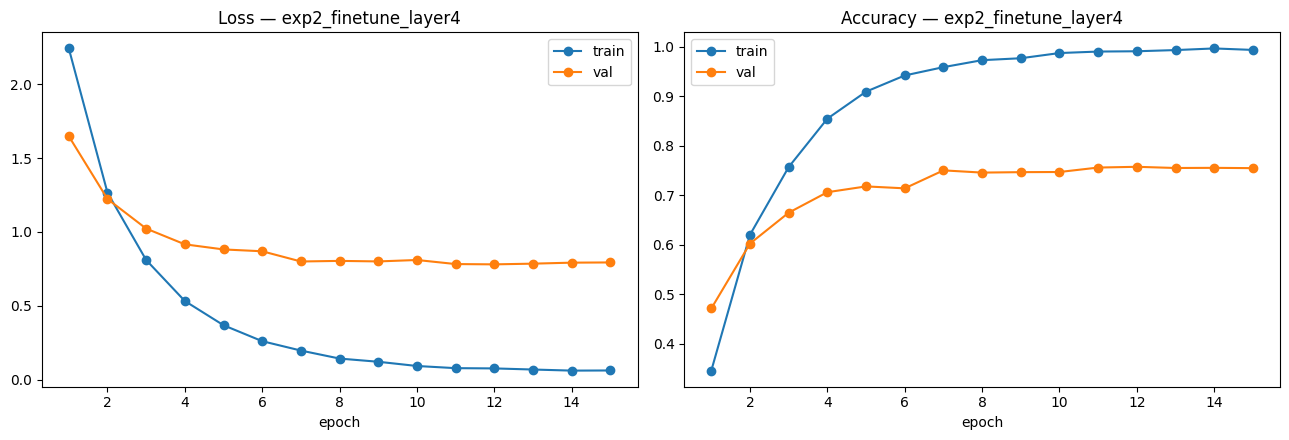

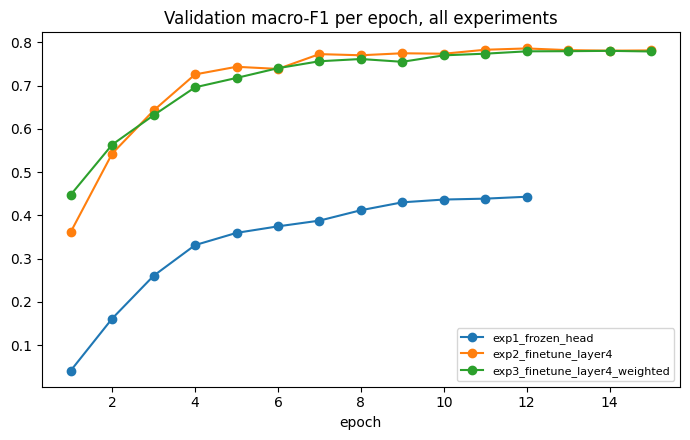

Final-epoch train-acc minus val-acc gap: 0.239  (a large positive gap suggests overfitting)


In [22]:
# ---- H.1 Learning curves (selected experiment + all experiments overlaid) ----
hist = pd.DataFrame(exp_results[selected_name]["history"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label="train"); axes[0].plot(hist["epoch"], hist["val_loss"], marker="o", label="val")
axes[0].set_title(f"Loss — {selected_name}"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist["epoch"], hist["train_acc"], marker="o", label="train"); axes[1].plot(hist["epoch"], hist["val_acc"], marker="o", label="val")
axes[1].set_title(f"Accuracy — {selected_name}"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "training_curves.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, r in exp_results.items():
    h = pd.DataFrame(r["history"]); ax.plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
ax.set_title("Validation macro-F1 per epoch, all experiments"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "experiments_val_f1.png", dpi=150); plt.show()

gap = hist["train_acc"].iloc[-1] - hist["val_acc"].iloc[-1]
print(f"Final-epoch train-acc minus val-acc gap: {gap:.3f}  (a large positive gap suggests overfitting)")

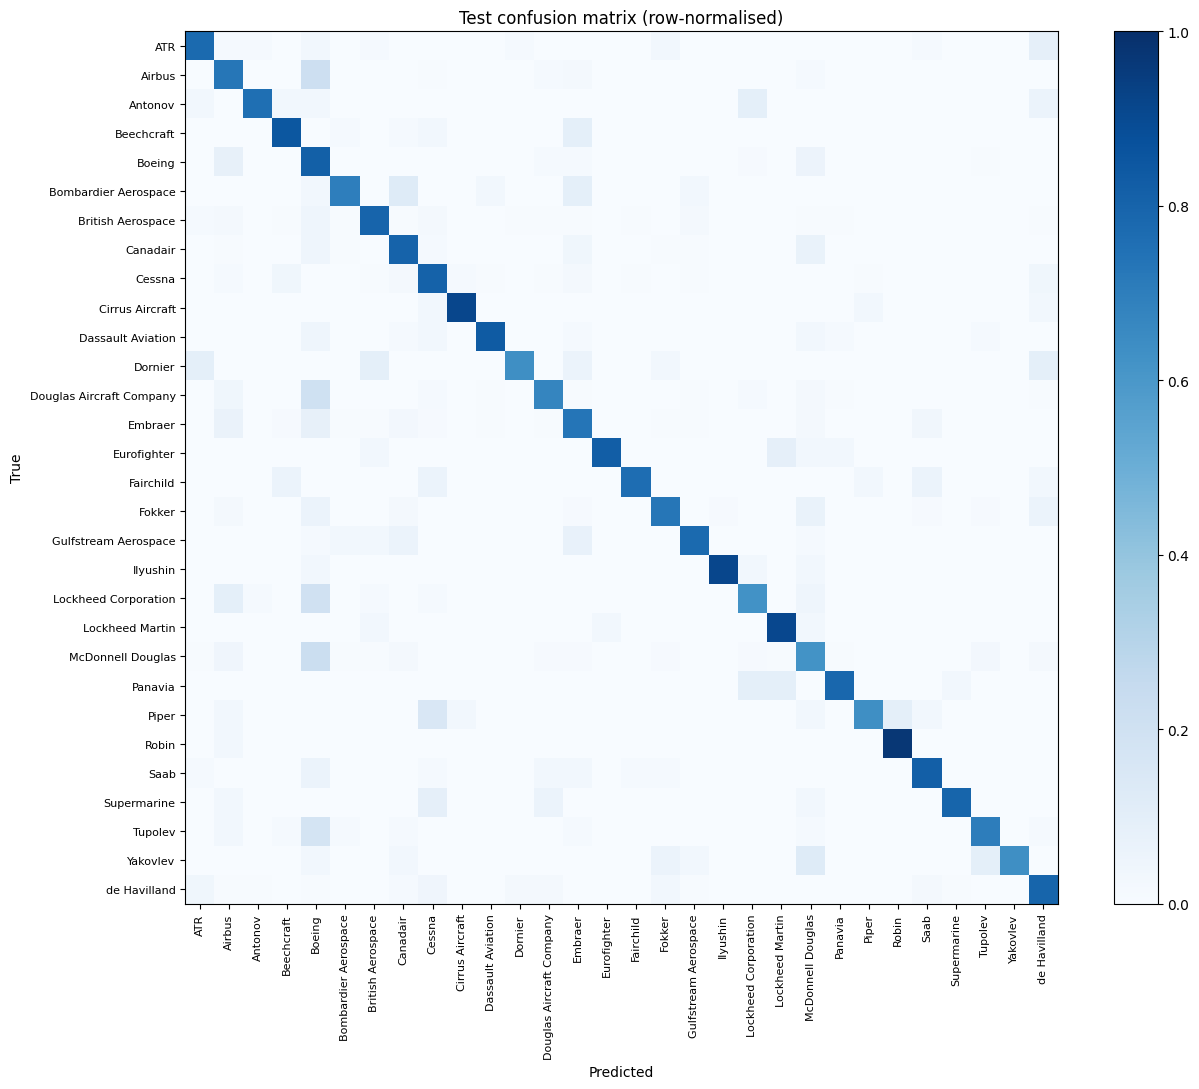

Most frequent confusions (count, TRUE -> PREDICTED):
   92  Airbus  ->  Boeing
   60  Boeing  ->  Airbus
   51  McDonnell Douglas  ->  Boeing
   41  Boeing  ->  McDonnell Douglas
   27  Douglas Aircraft Company  ->  Boeing
   19  Embraer  ->  Boeing
   15  Embraer  ->  Airbus
   13  Lockheed Corporation  ->  Boeing

5 weakest classes by F1 (with their training-set size):


,precision,recall,f1-score,support,train_count
McDonnell Douglas,0.623,0.618,0.621,233.0,232
Lockheed Corporation,0.683,0.621,0.651,66.0,68
Dornier,0.808,0.636,0.712,33.0,34
Douglas Aircraft Company,0.767,0.669,0.715,133.0,133
Bombardier Aerospace,0.742,0.697,0.719,33.0,33


5 strongest classes by F1:


,precision,recall,f1-score,support,train_count
Dassault Aviation,0.933,0.836,0.882,67.0,67
Eurofighter,0.966,0.824,0.889,34.0,33
Cirrus Aircraft,0.912,0.912,0.912,34.0,33
Ilyushin,0.969,0.912,0.939,34.0,33
Robin,0.917,0.971,0.943,34.0,33



Spearman correlation between training-set size and per-class F1: rho=-0.47 (p=0.009) — positive means rarer classes tend to do worse.


In [23]:
# ---- H.2 Confusion matrix (row-normalised: each row sums to 1 = recall per true class) ----
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(classes, rotation=90, fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(classes, fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Test confusion matrix (row-normalised)")
fig.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(PLOTS_DIR / "confusion_matrix.png", dpi=150); plt.show()

# ---- H.3 Evidence-based error analysis ----
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(int(off[i, j]), idx_to_class[i], idx_to_class[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0], reverse=True)
print("Most frequent confusions (count, TRUE -> PREDICTED):")
for c, t, p in pairs[:8]:
    print(f"  {c:3d}  {t}  ->  {p}")

print("\n5 weakest classes by F1 (with their training-set size):")
display(per_class.head(5)[["precision", "recall", "f1-score", "support", "train_count"]].round(3))
print("5 strongest classes by F1:")
display(per_class.tail(5)[["precision", "recall", "f1-score", "support", "train_count"]].round(3))

rho, pval = spearmanr(per_class["train_count"], per_class["f1-score"])
print(f"\nSpearman correlation between training-set size and per-class F1: rho={rho:.2f} (p={pval:.3f}) "
      "— positive means rarer classes tend to do worse.")

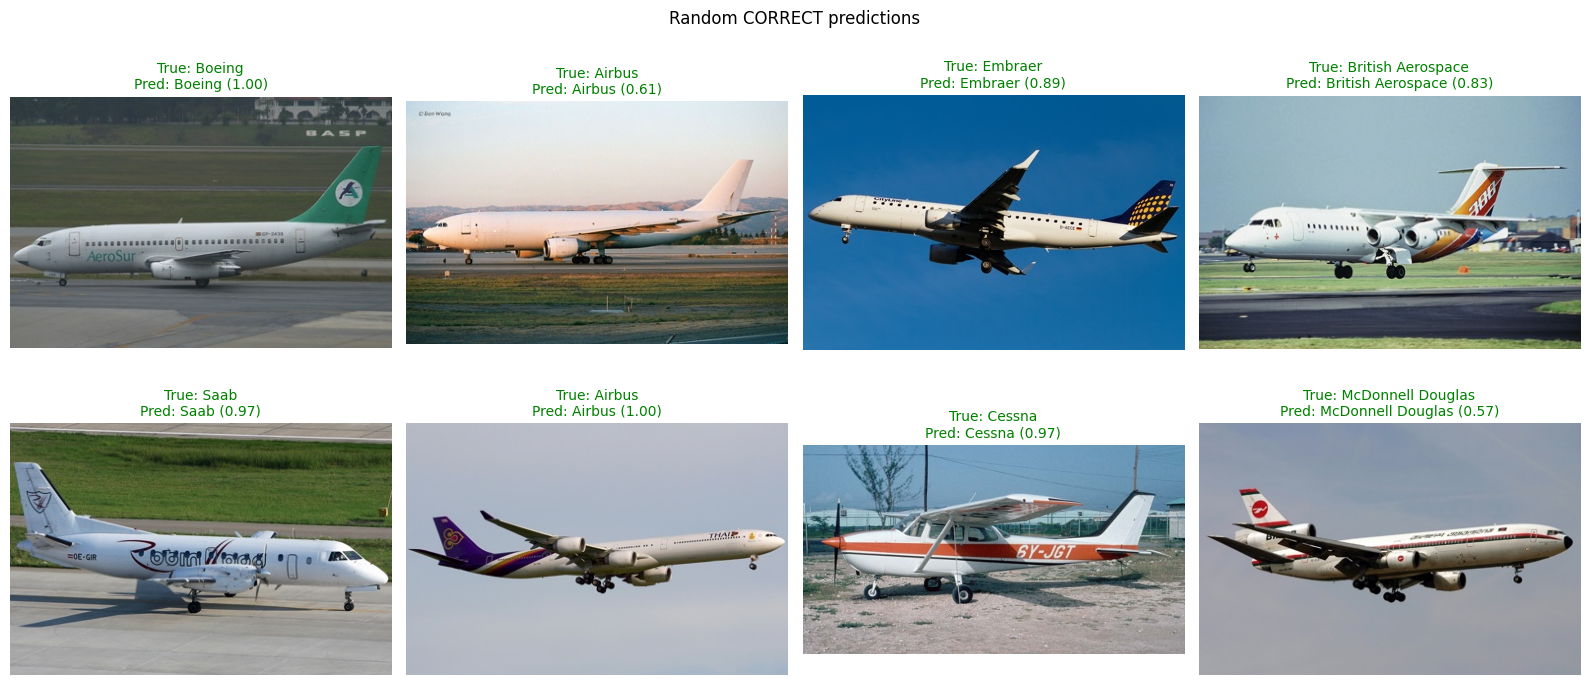

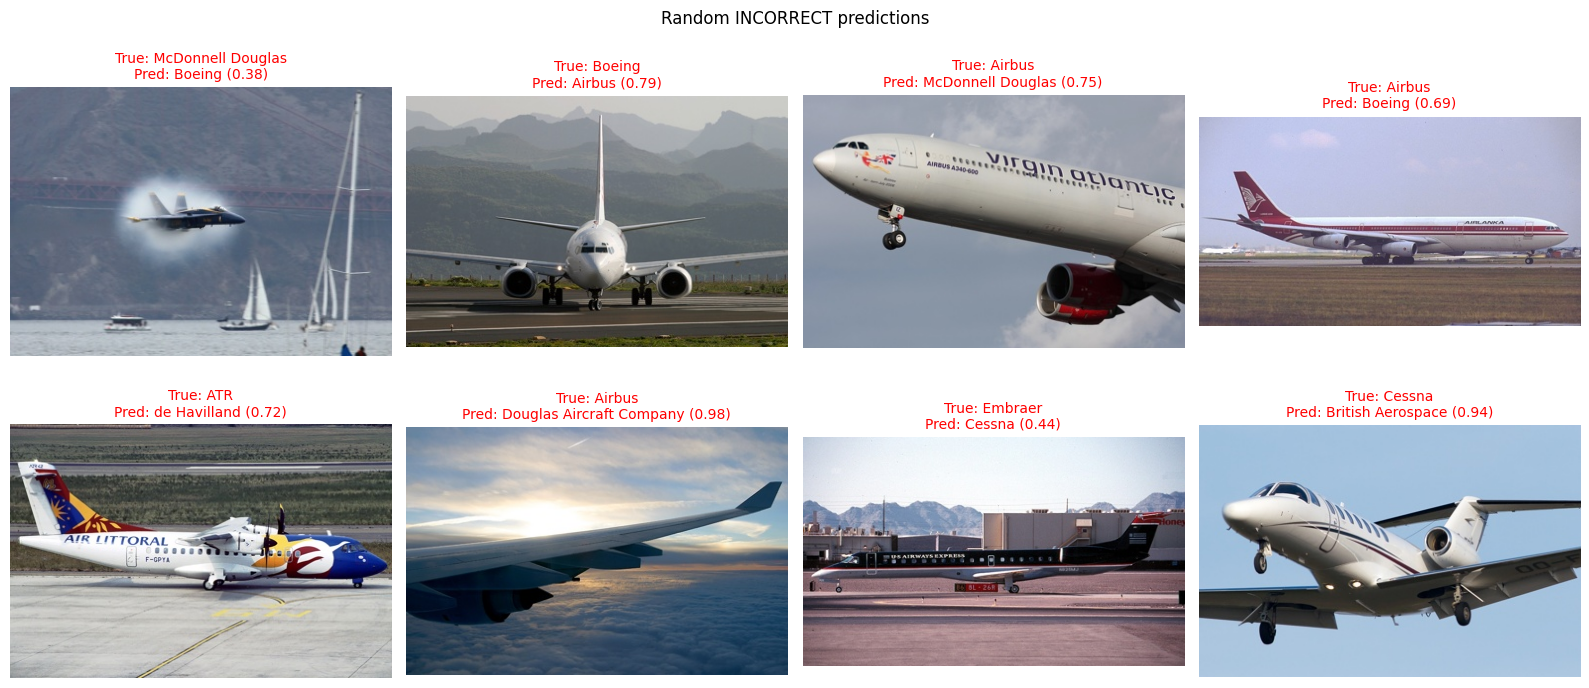

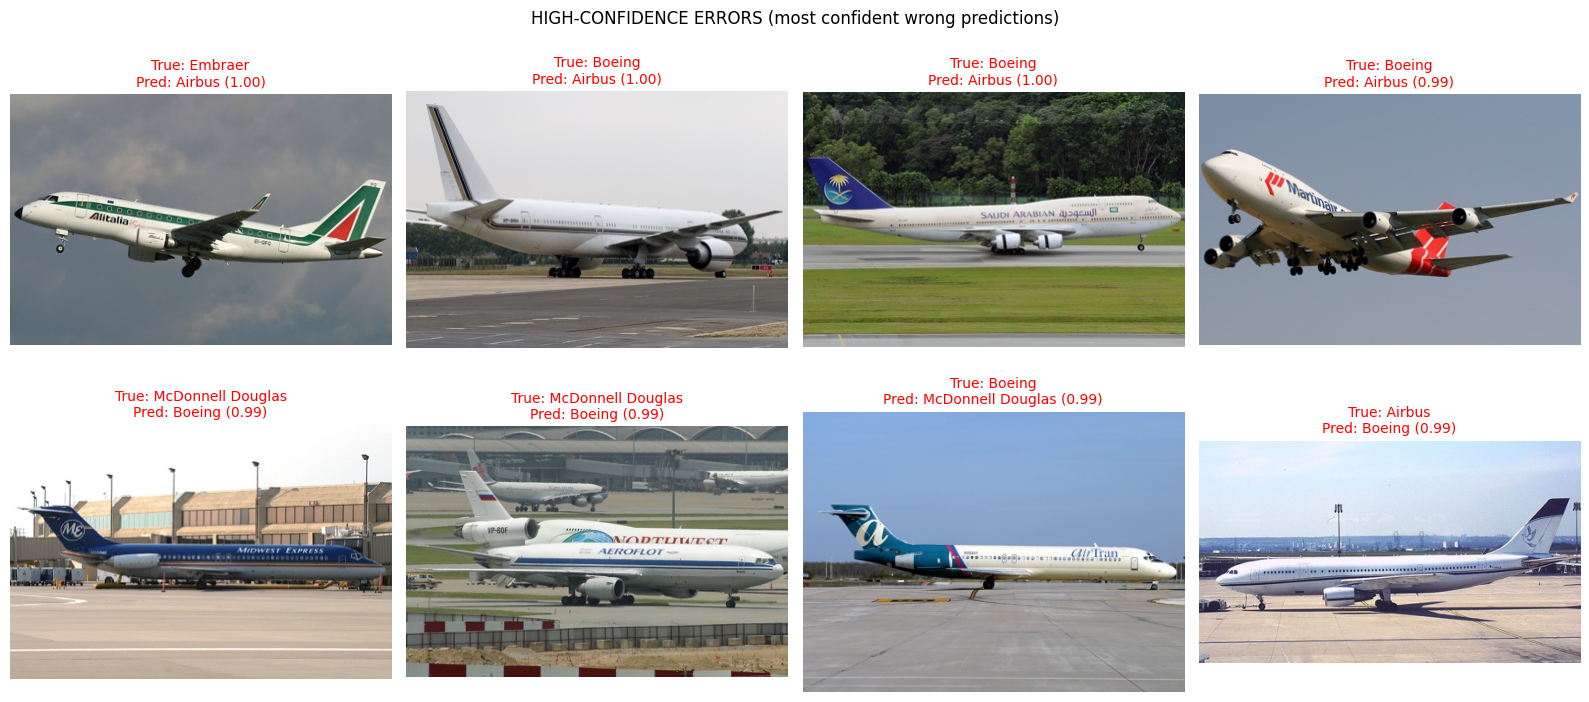

Mean confidence when correct: 0.851 | when wrong: 0.620
(if confidence when wrong is also high, the model is over-confident — probabilities should not be read as calibrated certainty)


In [24]:
# ---- H.4 Prediction galleries ----
pred_df = pd.DataFrame({
    "image_id": test_df["image_id"], "image_path": test_df["image_path"],
    "true_label": y_true, "true_name": [idx_to_class[i] for i in y_true],
    "pred_label": y_pred, "pred_name": [idx_to_class[i] for i in y_pred],
    "confidence": confidence, "correct": y_pred == y_true})

def show_gallery(sub: pd.DataFrame, title: str, fname: str, n: int = 8) -> None:
    sub = sub.head(n)
    if sub.empty:
        print(f"(no images for: {title})"); return
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), sub.iterrows()):
        with Image.open(r["image_path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"True: {r['true_name']}\nPred: {r['pred_name']} ({r['confidence']:.2f})", fontsize=10,
                     color="green" if r["correct"] else "red")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(PLOTS_DIR / fname, dpi=120); plt.show()

show_gallery(pred_df[pred_df.correct].sample(frac=1, random_state=SEED), "Random CORRECT predictions", "gallery_correct.png")
show_gallery(pred_df[~pred_df.correct].sample(frac=1, random_state=SEED), "Random INCORRECT predictions", "gallery_incorrect.png")
show_gallery(pred_df[~pred_df.correct].sort_values("confidence", ascending=False), "HIGH-CONFIDENCE ERRORS (most confident wrong predictions)", "gallery_high_conf_errors.png")

print(f"Mean confidence when correct: {pred_df[pred_df.correct].confidence.mean():.3f} | when wrong: {pred_df[~pred_df.correct].confidence.mean():.3f}")
print("(if confidence when wrong is also high, the model is over-confident — probabilities should not be read as calibrated certainty)")

### What the errors look like

- Most mistakes involve Boeing or Airbus. 358 of the 788 errors (45%) are predictions of one of the two, 247 (31%) are predictions of Boeing alone. Boeing precision is 0.708 against recall 0.815, so the model over-predicts it.
- Biggest confusions (true -> predicted): Airbus -> Boeing 92, Boeing -> Airbus 60, McDonnell Douglas -> Boeing 51, Boeing -> McDonnell Douglas 41, Douglas Aircraft Company -> Boeing 27.
- Mean confidence is 0.851 on correct predictions and 0.620 on wrong ones, but the most confident errors go up to 0.999. In the gallery they include what look like 747s and a 777 predicted as Airbus, and rear-engine jets mixed up between Boeing and McDonnell Douglas.
- Spearman correlation between class size and per-class F1 is -0.47 (p = 0.009): in this run the larger classes tended to score lower, not higher. Small classes have about 33 test images each, so their scores are noisy.

## Inference

`predict_image` uses exactly the same resize and normalisation as validation/test. The first example is an image from the test split, so it is a demo and not an independent test.

[Dataset example — test split] true label: Boeing


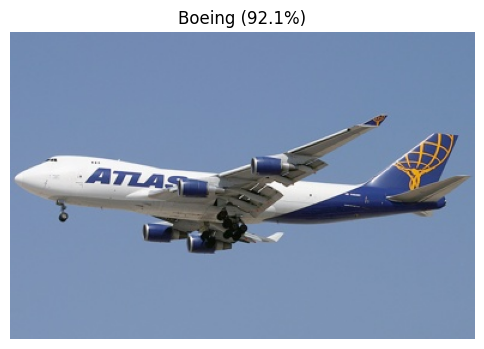

  Boeing                     92.1%
  Airbus                      7.1%
  McDonnell Douglas           0.2%


In [25]:
@torch.inference_mode()
def predict_image(image, model=None, k: int = 3, show: bool = True) -> dict:
    """image: file path or PIL image. Returns predicted class, confidence and top-k with probabilities."""
    model = final_model if model is None else model
    pil = Image.open(image).convert("RGB") if isinstance(image, (str, Path)) else image.convert("RGB")
    x = eval_tfms(pil).unsqueeze(0).to(DEVICE)
    model.eval()
    probs = torch.softmax(model(x), dim=1)[0].cpu()
    top_p, top_i = probs.topk(k)
    top_k = [(idx_to_class[int(i)], float(p)) for p, i in zip(top_p, top_i)]
    if show:
        plt.figure(figsize=(6, 4)); plt.imshow(pil); plt.axis("off")
        plt.title(f"{top_k[0][0]} ({top_k[0][1]:.1%})"); plt.show()
        for name, p in top_k:
            print(f"  {name:25s} {p:6.1%}")
    return {"predicted": top_k[0][0], "confidence": top_k[0][1], "top_k": top_k}

# ---- J.1 Example prediction on a DATASET test image (NOT an independent external test) ----
ex = test_df.sample(1, random_state=SEED).iloc[0]
print(f"[Dataset example — test split] true label: {ex['manufacturer']}")
_ = predict_image(ex["image_path"])

In [26]:
# ---- J.2 OPTIONAL: independent external-image test (your own photo or one from the web) ----
RUN_EXTERNAL = False
if RUN_EXTERNAL:
    from google.colab import files
    up = files.upload()                                   # choose one or more aircraft photos
    for fname in up:
        print(f"\n[External image] {fname}  (anecdotal demo — a few photos are NOT a benchmark)")
        _ = predict_image(fname)

In [27]:
# ---- J.3 OPTIONAL: tiny free web demo with Gradio (the notebook works without it) ----
RUN_GRADIO = False
if RUN_GRADIO:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr
    def gradio_predict(pil_img):
        out = predict_image(pil_img, show=False, k=3)
        return {name: p for name, p in out["top_k"]}
    gr.Interface(fn=gradio_predict, inputs=gr.Image(type="pil"), outputs=gr.Label(num_top_classes=3),
                 title="Aircraft manufacturer classifier",
                 description="ResNet-18 transfer learning on FGVC-Aircraft (manufacturer level).").launch(share=True)

## Saving results

Best checkpoint, class mapping, histories, metrics, per-class report, test predictions, confusion matrix, plots and the experiment config are written to `aircraft_outputs/` and zipped.

In [28]:
# ---- K.1 Write artifacts ----
def to_py(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, Path): return str(o)
    raise TypeError(type(o))

shutil.copy(exp_results[selected_name]["ckpt_path"], OUTPUT_DIR / "best_model.pt")
(OUTPUT_DIR / "class_to_idx.json").write_text(json.dumps(class_to_idx, indent=2))

for name, r in exp_results.items():
    pd.DataFrame(r["history"]).to_csv(RESULTS_DIR / f"history_{name}.csv", index=False)
exp_table.to_csv(RESULTS_DIR / "experiments_validation_summary.csv")
comparison_df.to_csv(RESULTS_DIR / "test_comparison_baselines_vs_model.csv")
per_class.to_csv(RESULTS_DIR / "per_class_report_test.csv")
pd.DataFrame(cm, index=classes, columns=classes).to_csv(RESULTS_DIR / "confusion_matrix_test_counts.csv")
pred_df.drop(columns=["image_path"]).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
(RESULTS_DIR / "test_metrics.json").write_text(json.dumps(test_metrics, indent=2, default=to_py))

env_info = {"python": sys.version.split()[0], "torch": torch.__version__, "torchvision": torchvision.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__, "pillow": Image.__version__,
            "device": str(DEVICE), "gpu": GPU_NAME, "platform": platform.platform()}
config = {"created_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(), "seed": SEED, "hardware_profile": HW,
          "img_size": IMG_SIZE, "cache_short_side": CACHE_SHORT_SIDE, "banner_cropped_px": BANNER_PX,
          "normalisation": {"mean": MEAN, "std": STD}, "num_classes": NUM_CLASSES,
          "split_sizes": {s: len(dfs[s]) for s in SPLITS}, "experiments": EXPERIMENTS, "experiments_run": list(exp_results),
          "selected_experiment": selected_name, "selection_rule": "highest validation macro-F1",
          "baseline_validation_metrics": baseline_val, "environment": env_info}
(RESULTS_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2, default=to_py))
(RESULTS_DIR / "requirements_snapshot.txt").write_text(
    f"torch=={torch.__version__}\ntorchvision=={torchvision.__version__}\nnumpy=={np.__version__}\n"
    f"pandas=={pd.__version__}\nscikit-learn=={sklearn.__version__}\npillow=={Image.__version__}\n"
    f"matplotlib=={matplotlib.__version__}\nscipy\ntqdm\n")

# ---- K.2 ZIP ----
zip_path = shutil.make_archive("/content/aircraft_results", "zip", root_dir=OUTPUT_DIR)
print("Saved files:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {str(p.relative_to(OUTPUT_DIR)):55s} {p.stat().st_size / 1e6:8.2f} MB")
print("\nZIP:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    pass

Saved files:
  best_model.pt                                              44.85 MB
  checkpoints/exp1_frozen_head_best.pt                       44.85 MB
  checkpoints/exp2_finetune_layer4_best.pt                   44.85 MB
  checkpoints/exp3_finetune_layer4_weighted_best.pt          44.85 MB
  class_to_idx.json                                           0.00 MB
  plots/class_distribution.png                                0.11 MB
  plots/confusion_matrix.png                                  0.16 MB
  plots/experiments_val_f1.png                                0.06 MB
  plots/gallery_correct.png                                   1.34 MB
  plots/gallery_high_conf_errors.png                          1.36 MB
  plots/gallery_incorrect.png                                 1.39 MB
  plots/sample_images.png                                     1.77 MB
  plots/training_curves.png                                   0.08 MB
  results/confusion_matrix_test_counts.csv                    0.00 MB
  resul